In [17]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt


# Recursive matrix multiplication using Binét's method

In [18]:
def generate_random_matrix(size: int, low: float = 0.00000001, high: float = 1.0):
    """ returns matrix size x size with random values in range of (low, high) """

    return high - (high - low) * np.random.rand(size, size)


def next_pow2(n: int) -> int:
    if n <= 1:
        return 1
    return 1 << (n - 1).bit_length()


def next_pow3(n: int) -> int:
    p = 1
    while p < n:
        p *= 3
    return p


def report(size, expected, got, m_ops, a_s_ops):
    print(
        f"{size} {np.array_equal(expected, got)} "
        f"{np.allclose(expected, got)} {m_ops} {a_s_ops}"
    )


sizes = [2, 4, 10, 20, 50, 100]
A_multiple = [generate_random_matrix(size) for size in sizes]
B_multiple = [generate_random_matrix(size) for size in sizes]


In [19]:
def binet(A, B):
    m_ops = 0
    a_s_ops = 0

    def rec(A_i_s, A_i_e, A_j_s, A_j_e,
            B_i_s, B_i_e, B_j_s, B_j_e):
        nonlocal m_ops, a_s_ops

        if A_i_e - A_i_s == 1:
            m_ops += 1
            return np.array([[A_padded[A_i_s][A_j_s] * B_padded[B_i_s][B_j_s]]])

        mid_i_A = A_i_s + (A_i_e - A_i_s) // 2
        mid_j_A = A_j_s + (A_j_e - A_j_s) // 2

        se_11_A = ((A_i_s, mid_i_A), (A_j_s, mid_j_A))
        se_12_A = ((A_i_s, mid_i_A), (mid_j_A, A_j_e))
        se_21_A = ((mid_i_A, A_i_e), (A_j_s, mid_j_A))
        se_22_A = ((mid_i_A, A_i_e), (mid_j_A, A_j_e))

        mid_i_B = B_i_s + (B_i_e - B_i_s) // 2
        mid_j_B = B_j_s + (B_j_e - B_j_s) // 2

        se_11_B = ((B_i_s, mid_i_B), (B_j_s, mid_j_B))
        se_12_B = ((B_i_s, mid_i_B), (mid_j_B, B_j_e))
        se_21_B = ((mid_i_B, B_i_e), (B_j_s, mid_j_B))
        se_22_B = ((mid_i_B, B_i_e), (mid_j_B, B_j_e))

        C_11 = (rec(*se_11_A[0], *se_11_A[1], *se_11_B[0], *se_11_B[1]) +
                rec(*se_12_A[0], *se_12_A[1], *se_21_B[0], *se_21_B[1]))
        a_s_ops += C_11.size

        C_12 = (rec(*se_11_A[0], *se_11_A[1], *se_12_B[0], *se_12_B[1]) +
                rec(*se_12_A[0], *se_12_A[1], *se_22_B[0], *se_22_B[1]))
        a_s_ops += C_12.size

        C_21 = (rec(*se_21_A[0], *se_21_A[1], *se_11_B[0], *se_11_B[1]) +
                rec(*se_22_A[0], *se_22_A[1], *se_21_B[0], *se_21_B[1]))
        a_s_ops += C_21.size

        C_22 = (rec(*se_21_A[0], *se_21_A[1], *se_12_B[0], *se_12_B[1]) +
                rec(*se_22_A[0], *se_22_A[1], *se_22_B[0], *se_22_B[1]))
        a_s_ops += C_22.size

        return np.block([[C_11, C_12], [C_21, C_22]])

    m_A, n_A = A.shape
    m_B, n_B = B.shape

    if n_A != m_B:
        raise Exception

    n = next_pow2(max(m_A, n_A, m_B, n_B))
    A_padded = np.pad(A, ((0, n - m_A), (0, n - n_A)), mode='constant')
    B_padded = np.pad(B, ((0, n - m_B), (0, n - n_B)), mode='constant')
    result = rec(0, n, 0, n, 0, n, 0, n)[:m_A, :n_B]
    return result, m_ops, a_s_ops


In [20]:
print("size equal close m_ops a_s_ops")
for idx in range(len(sizes)):
    A = A_multiple[idx]
    B = B_multiple[idx]
    got, m_ops, a_s_ops = binet(A, B)
    report(sizes[idx], A @ B, got, m_ops, a_s_ops)


size equal close m_ops a_s_ops
2 False True 8 4
4 False True 64 48
10 False True 4096 3840
20 False True 32768 31744
50 False True 262144 258048
100 False True 2097152 2080768


# Recursive matrix multiplication using Strassen's method

In [21]:
def strassen(A, B):
    m_ops = 0
    a_s_ops = 0

    def add(X, Y):
        nonlocal m_ops, a_s_ops
        a_s_ops += X.size
        return X + Y

    def sub(X, Y):
        nonlocal a_s_ops
        a_s_ops += X.size
        return X - Y

    def rec(X, Y):
        nonlocal m_ops
        n = X.shape[0]

        if n == 1:
            m_ops += 1
            return np.array([[X[0, 0] * Y[0, 0]]])

        mid = n // 2

        A11 = X[:mid, :mid]
        A12 = X[:mid, mid:]
        A21 = X[mid:, :mid]
        A22 = X[mid:, mid:]

        B11 = Y[:mid, :mid]
        B12 = Y[:mid, mid:]
        B21 = Y[mid:, :mid]
        B22 = Y[mid:, mid:]

        M1 = rec(add(A11, A22), add(B11, B22))
        M2 = rec(add(A21, A22), B11)
        M3 = rec(A11, sub(B12, B22))
        M4 = rec(A22, sub(B21, B11))
        M5 = rec(add(A11, A12), B22)
        M6 = rec(sub(A21, A11), add(B11, B12))
        M7 = rec(sub(A12, A22), add(B21, B22))

        C11 = add(sub(add(M1, M4), M5), M7)
        C12 = add(M3, M5)
        C21 = add(M2, M4)
        C22 = add(sub(add(M1, M3), M2), M6)

        return np.block([[C11, C12], [C21, C22]])

    m_A, n_A = A.shape
    m_B, n_B = B.shape

    if n_A != m_B:
        raise Exception

    n = next_pow2(max(m_A, n_A, m_B, n_B))
    A_padded = np.pad(A, ((0, n - m_A), (0, n - n_A)), mode='constant')
    B_padded = np.pad(B, ((0, n - m_B), (0, n - n_B)), mode='constant')
    result = rec(A_padded, B_padded)[:m_A, :n_B]
    return result, m_ops, a_s_ops


In [22]:
print("size equal close m_ops a_s_ops")
for idx in range(len(sizes)):
    A = A_multiple[idx]
    B = B_multiple[idx]
    got, m_ops, a_s_ops = strassen(A, B)
    report(sizes[idx], A @ B, got, m_ops, a_s_ops)


size equal close m_ops a_s_ops
2 False True 7 18
4 False True 49 198
10 False True 2401 12870
20 False True 16807 94698
50 False True 117649 681318
100 False True 823543 4842954


# Matrix multiplication using AlphaTensor (AI / Nature)

In [23]:
factorizations = dict(np.load("alphatensor/factorizations_r.npz", allow_pickle=True))

square_sizes = [2, 3, 4, 5, 9, 10, 11]
for n in square_sizes:
    u, _, _ = factorizations[f"{n},{n},{n}"]
    print(f"{n}x{n} factorization rank: {u.shape[-1]}")


def alphatensor(A, B):
    """AlphaTensor square multiply from factorizations_r.npz. Returns (C, m_ops, a_s_ops)."""
    if A.shape != B.shape or A.shape[0] != A.shape[1]:
        raise ValueError("alphatensor supports only square matrices of equal size")

    n = A.shape[0]
    key = f"{n},{n},{n}"
    if key not in factorizations:
        raise ValueError(f"no AlphaTensor factorization for {n}x{n}")

    u, v, w = factorizations[key]
    m_ops = 0
    a_s_ops = 0
    entries = n * n
    A_flat = A.reshape(-1)
    B_flat = B.reshape(-1)
    rank = u.shape[-1]

    S = np.zeros(rank)
    T = np.zeros(rank)

    def apply_coef(acc, value, coef, first):
        nonlocal m_ops, a_s_ops
        if coef == 1:
            term = value
        elif coef == -1:
            term = -value
        else:
            term = coef * value
            m_ops += 1
        if first:
            return term, False
        a_s_ops += 1
        return acc + term, False

    for r in range(rank):
        first = True
        for i in range(entries):
            coef = u[i, r]
            if coef == 0:
                continue
            S[r], first = apply_coef(S[r], A_flat[i], coef, first)

        first = True
        for j in range(entries):
            coef = v[j, r]
            if coef == 0:
                continue
            T[r], first = apply_coef(T[r], B_flat[j], coef, first)

    P = S * T
    m_ops += rank

    C_sym_flat = np.zeros(entries)
    for k in range(entries):
        first = True
        for r in range(rank):
            coef = w[k, r]
            if coef == 0:
                continue
            C_sym_flat[k], first = apply_coef(C_sym_flat[k], P[r], coef, first)

    # factorization builds (A @ B).T
    C = C_sym_flat.reshape(n, n).T
    return C, m_ops, a_s_ops


2x2 factorization rank: 7
3x3 factorization rank: 23
4x4 factorization rank: 49
5x5 factorization rank: 98
9x9 factorization rank: 498
10x10 factorization rank: 682
11x11 factorization rank: 896


In [24]:
print("size equal close m_ops a_s_ops")
for n in square_sizes:
    A = generate_random_matrix(n)
    B = generate_random_matrix(n)
    got, m_ops, a_s_ops = alphatensor(A, B)
    report(n, A @ B, got, m_ops, a_s_ops)


size equal close m_ops a_s_ops
2 False True 7 22
3 False True 31 110
4 False True 49 468
5 False True 103 643
9 False True 7192 18289
10 False True 871 10862
11 False True 12506 33500


# Performance charts

In [25]:
plot_sizes = [2, 3, 4, 5, 6, 8, 9, 12, 16, 18, 24, 27, 32, 50, 100]

binet_times, strassen_times = [], []
binet_m_ops, strassen_m_ops = [], []
binet_a_s_ops, strassen_a_s_ops = [], []
ai_sizes, ai_times, ai_m_ops, ai_a_s_ops = [], [], [], []

for n in plot_sizes:
    A = generate_random_matrix(n)
    B = generate_random_matrix(n)

    t0 = time.perf_counter()
    _, m_ops, a_s_ops = binet(A, B)
    binet_times.append(time.perf_counter() - t0)
    binet_m_ops.append(m_ops)
    binet_a_s_ops.append(a_s_ops)

    t0 = time.perf_counter()
    _, m_ops, a_s_ops = strassen(A, B)
    strassen_times.append(time.perf_counter() - t0)
    strassen_m_ops.append(m_ops)
    strassen_a_s_ops.append(a_s_ops)

for n in square_sizes:
    A = generate_random_matrix(n)
    B = generate_random_matrix(n)

    t0 = time.perf_counter()
    _, m_ops, a_s_ops = alphatensor(A, B)
    ai_sizes.append(n)
    ai_times.append(time.perf_counter() - t0)
    ai_m_ops.append(m_ops)
    ai_a_s_ops.append(a_s_ops)


def plot_with_fits(x, y, label):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    line, = plt.plot(x, y, "o-", label=label)
    color = line.get_color()
    xs = np.linspace(x.min(), x.max(), 200)
    linear = np.polyfit(x, y, 1)
    quadratic = np.polyfit(x, y, 2)
    plt.plot(xs, np.polyval(linear, xs), "--", color=color, label=f"{label} linear")
    plt.plot(xs, np.polyval(quadratic, xs), ":", color=color, label=f"{label} quadratic")


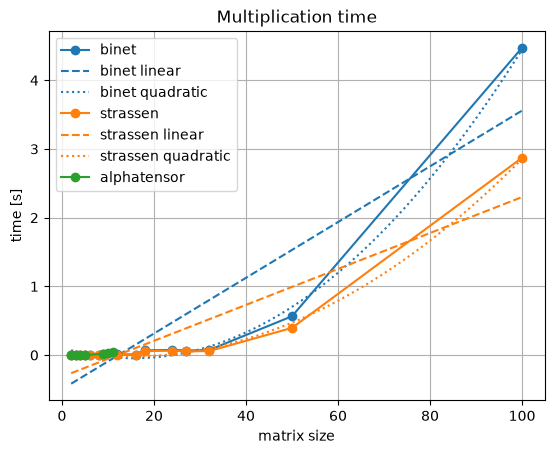

In [26]:
plot_with_fits(plot_sizes, binet_times, "binet")
plot_with_fits(plot_sizes, strassen_times, "strassen")
plt.plot(ai_sizes, ai_times, "o-", label="alphatensor")
plt.title("Multiplication time")
plt.xlabel("matrix size")
plt.ylabel("time [s]")
plt.legend()
plt.grid(True)
plt.show()


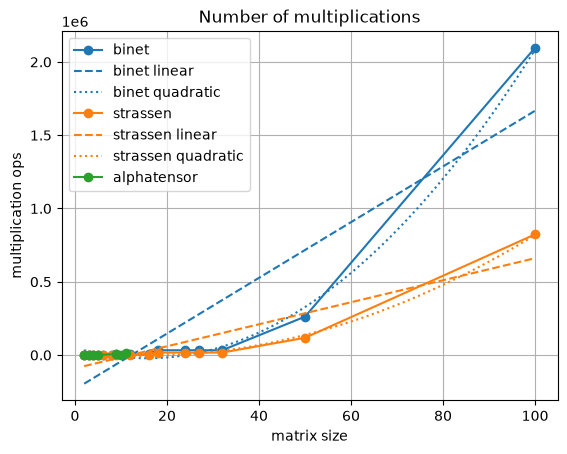

In [27]:
plot_with_fits(plot_sizes, binet_m_ops, "binet")
plot_with_fits(plot_sizes, strassen_m_ops, "strassen")
plt.plot(ai_sizes, ai_m_ops, "o-", label="alphatensor")
plt.title("Number of multiplications")
plt.xlabel("matrix size")
plt.ylabel("multiplication ops")
plt.legend()
plt.grid(True)
plt.show()


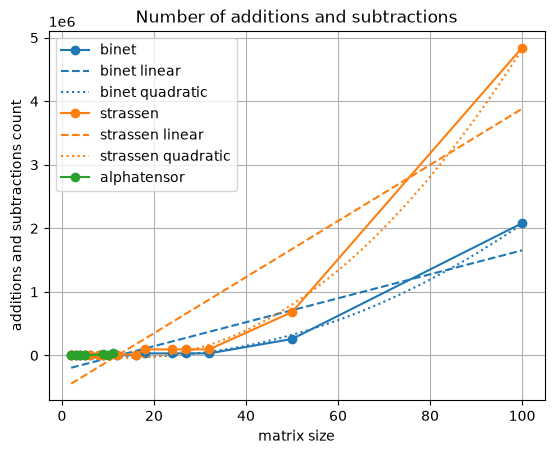

In [28]:
plot_with_fits(plot_sizes, binet_a_s_ops, "binet")
plot_with_fits(plot_sizes, strassen_a_s_ops, "strassen")
plt.plot(ai_sizes, ai_a_s_ops, "o-", label="alphatensor")
plt.title("Number of additions and subtractions")
plt.xlabel("matrix size")
plt.ylabel("additions and subtractions count")
plt.legend()
plt.grid(True)
plt.show()
